# Phase 1 - Audio & reference-annotation explorer
Inspect each prepared recording: metadata, waveform, per-speaker timeline lanes, overlap regions, speaker count, and audio playback.
Run from the `notebooks/` folder (or anywhere - paths are resolved from the project root).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from preprocessing.rttm import read_rttm, compute_stats
from preprocessing.audio_processor import get_audio_metadata

manifest = pd.read_csv(ROOT / "data/metadata/dataset_manifest.csv")
pd.set_option("display.width", 200, "display.max_columns", 30)
manifest[["recording_id", "dataset", "original_split", "duration_s", "num_speakers", "sample_rate",
          "channels", "language", "has_overlap", "overlap_ratio_of_speech", "num_segments"]]

,recording_id,dataset,original_split,duration_s,num_speakers,sample_rate,channels,language,has_overlap,overlap_ratio_of_speech,num_segments
0,ES2004a,AMI Meeting Corpus,test,1049.355,4,16000,1,en,True,0.1579,260
1,IS1009a,AMI Meeting Corpus,test,838.833,4,16000,1,en,True,0.1357,195
2,TS3003a,AMI Meeting Corpus,test,1505.643,4,16000,1,en,True,0.0458,242


## Helpers

In [2]:
PALETTE = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756", "#72B7B2", "#9D755D", "#BAB0AC"]

def load(rid):
    row = manifest.set_index("recording_id").loc[rid]
    data, sr = sf.read(ROOT / row.audio_filename, dtype="float32")
    return data, sr, read_rttm(ROOT / row.annotation_filename)

def overlap_regions(df):
    """Intervals where >= 2 segments are active."""
    ev = sorted([(s, 1) for s in df.start] + [(e, -1) for e in df.end])
    out, active, t0 = [], 0, None
    for t, d in ev:
        was = active; active += d
        if was < 2 <= active: t0 = t
        elif was >= 2 > active: out.append((t0, t))
    return out

def plot_recording(rid, t_start=0, t_end=None):
    data, sr, df = load(rid)
    t_end = t_end or len(data) / sr
    spk = sorted(df.speaker.unique())
    colors = {s: PALETTE[i % len(PALETTE)] for i, s in enumerate(spk)}
    fig, (aw, at) = plt.subplots(2, 1, figsize=(14, 2 + 0.6 * len(spk) + 2), sharex=True,
                                 gridspec_kw={"height_ratios": [1.2, max(1, len(spk) * 0.6)]})
    i0, i1 = int(t_start * sr), int(t_end * sr)
    seg = data[i0:i1]; step = max(1, len(seg) // 6000)           # min/max envelope for speed
    n = len(seg) // step
    blocks = seg[: n * step].reshape(n, step)
    tt = t_start + np.arange(n) * step / sr
    aw.fill_between(tt, blocks.min(1), blocks.max(1), color="#555", lw=0)
    aw.set_ylabel("amplitude"); aw.set_title(f"{rid} - waveform ({(t_end - t_start):.0f}s shown)")
    for k, s in enumerate(spk):
        for r in df[df.speaker == s].itertuples():
            if r.end < t_start or r.start > t_end: continue
            at.barh(k, r.duration, left=r.start, height=0.7, color=colors[s], edgecolor="none")
    for a, b in overlap_regions(df):
        if b < t_start or a > t_end: continue
        at.axvspan(a, b, color="red", alpha=0.25, lw=0)
        aw.axvspan(a, b, color="red", alpha=0.2, lw=0)
    at.set_yticks(range(len(spk))); at.set_yticklabels(spk); at.invert_yaxis()
    at.set_xlim(t_start, t_end); at.set_xlabel("time (s)  -  red shading = overlapping speech")
    plt.tight_layout(); plt.show()

def summary(rid):
    row = manifest.set_index("recording_id").loc[rid]
    _, _, df = load(rid)
    st = compute_stats(df)
    m = get_audio_metadata(ROOT / row.audio_filename)
    per = df.groupby("speaker").duration.sum().sort_values(ascending=False).round(1)
    print(f"{rid}: {m.duration_s:.1f}s | {m.sample_rate} Hz | {m.channels} ch | {m.subtype} | speakers={st.n_speakers} | "
          f"segments={st.n_segments} | speech={st.speech_s:.0f}s | overlap={st.overlap_s:.0f}s ({st.overlap_ratio:.1%} of speech)")
    display(per.rename("speaking time (s)").to_frame().T)

def play(rid, start, end):
    data, sr, _ = load(rid)
    display(Audio(data[int(start * sr): int(end * sr)], rate=sr))

## Per-recording summary, full-length waveform and speaker timeline

ES2004a: 1049.4s | 16000 Hz | 1 ch | PCM_16 | speakers=4 | segments=260 | speech=787s | overlap=124s (15.8% of speech)


speaker,FEE013,FEE016,MEE014,MEO015
speaking time (s),389.9,265.5,162.8,105.2


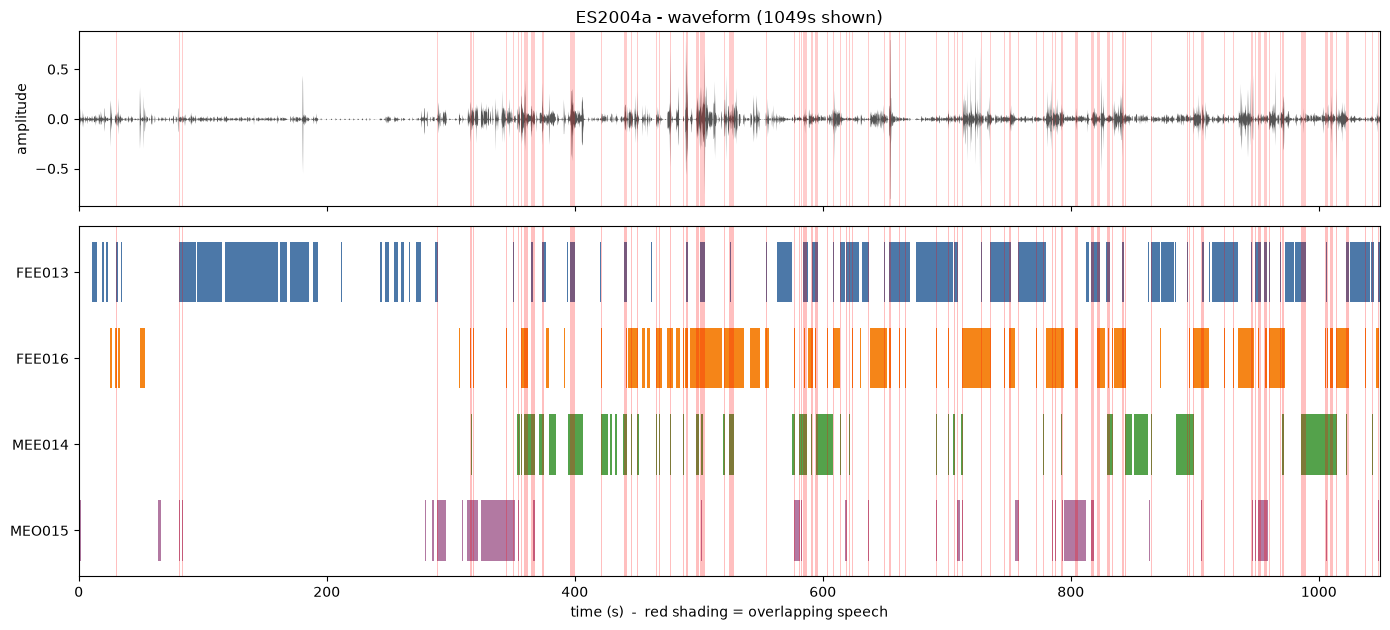

IS1009a: 838.8s | 16000 Hz | 1 ch | PCM_16 | speakers=4 | segments=195 | speech=605s | overlap=82s (13.6% of speech)


speaker,FIE088,FIO089,FIO087,FIO084
speaking time (s),412.5,144.3,70.9,68.2


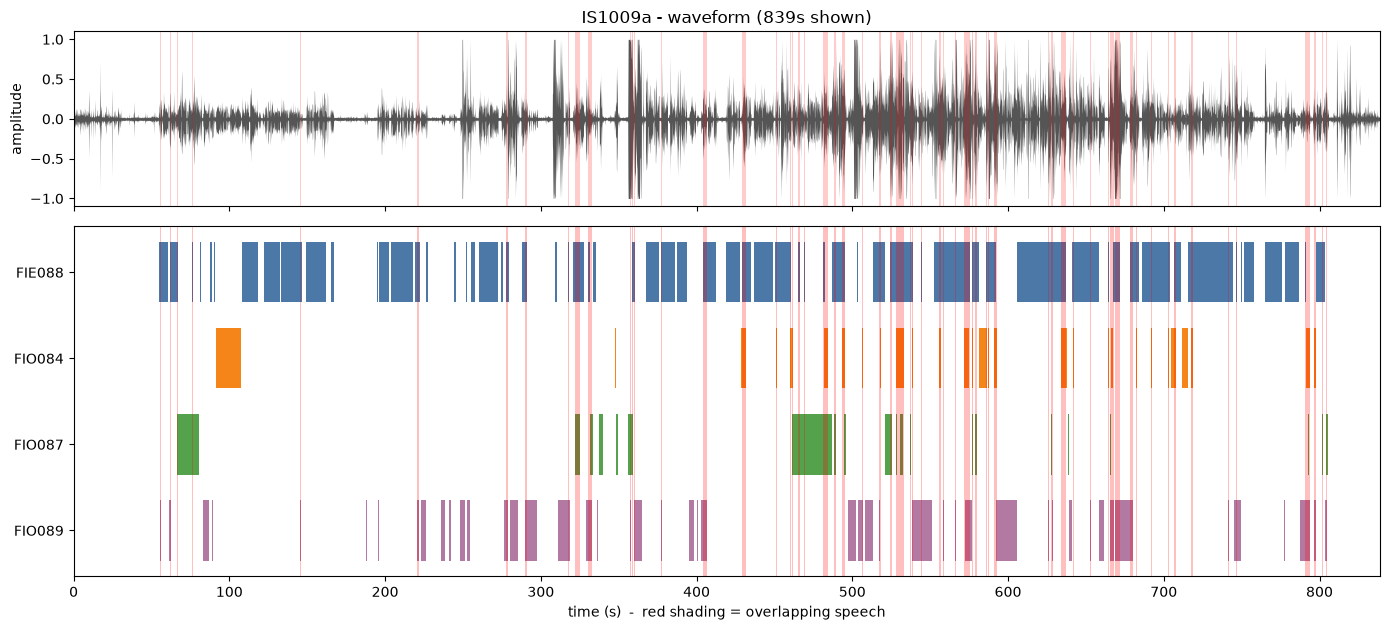

TS3003a: 1505.6s | 16000 Hz | 1 ch | PCM_16 | speakers=4 | segments=242 | speech=978s | overlap=45s (4.6% of speech)


speaker,MTD009PM,MTD012ME,MTD011UID,MTD0010ID
speaking time (s),850.4,109.5,39.6,26.5


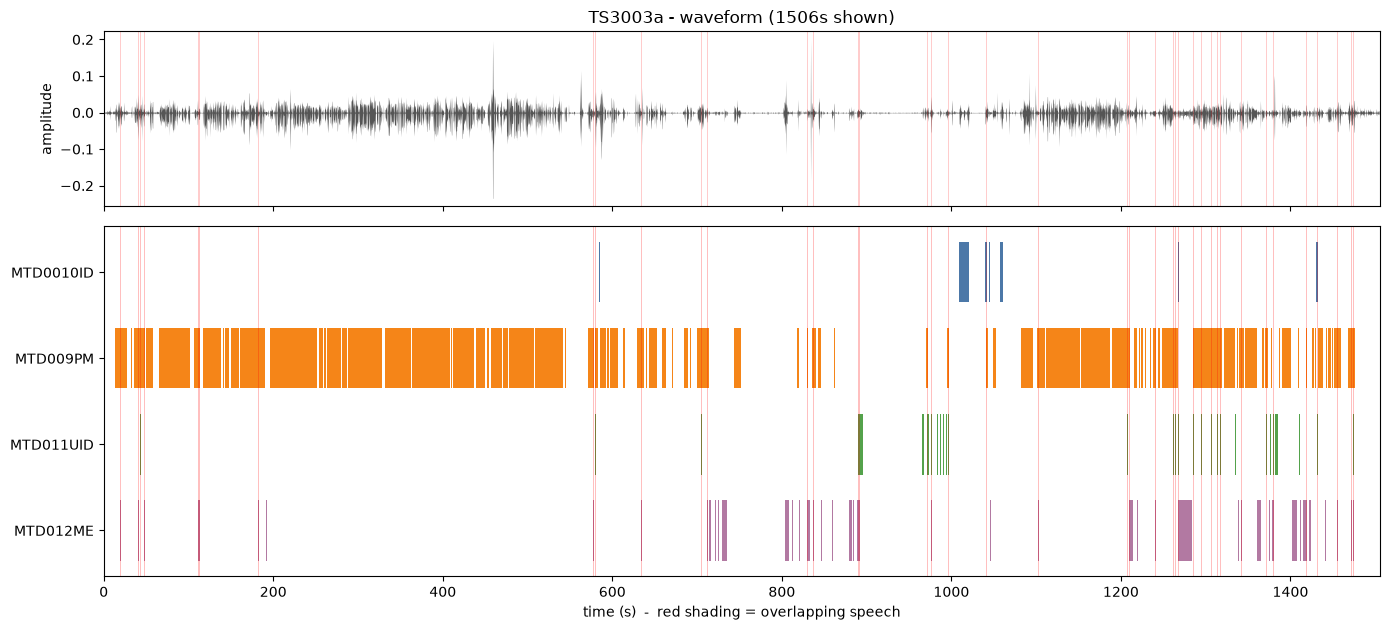

In [3]:
for rid in manifest.recording_id:
    summary(rid)
    plot_recording(rid)

## Zoom on an overlap region (first overlap longer than 1 s) with playback

ES2004a: 35 overlap regions > 1 s; zooming on 80.5-81.7s


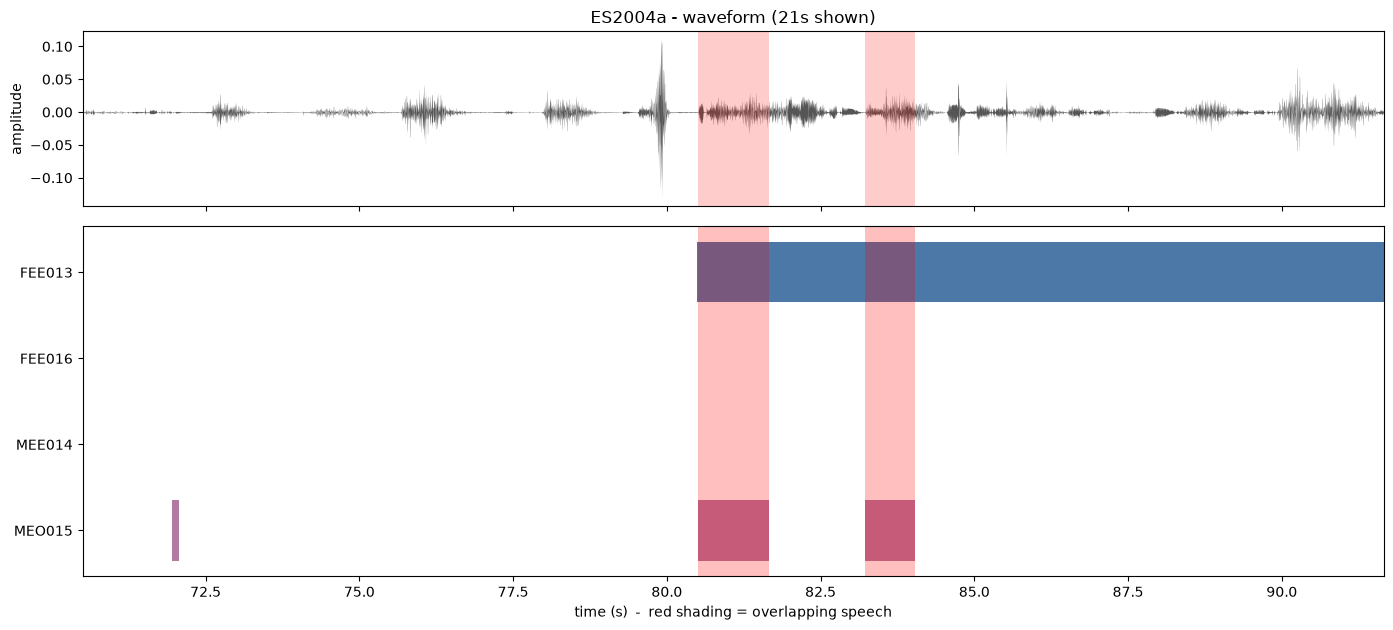

IS1009a: 26 overlap regions > 1 s; zooming on 220.5-221.5s


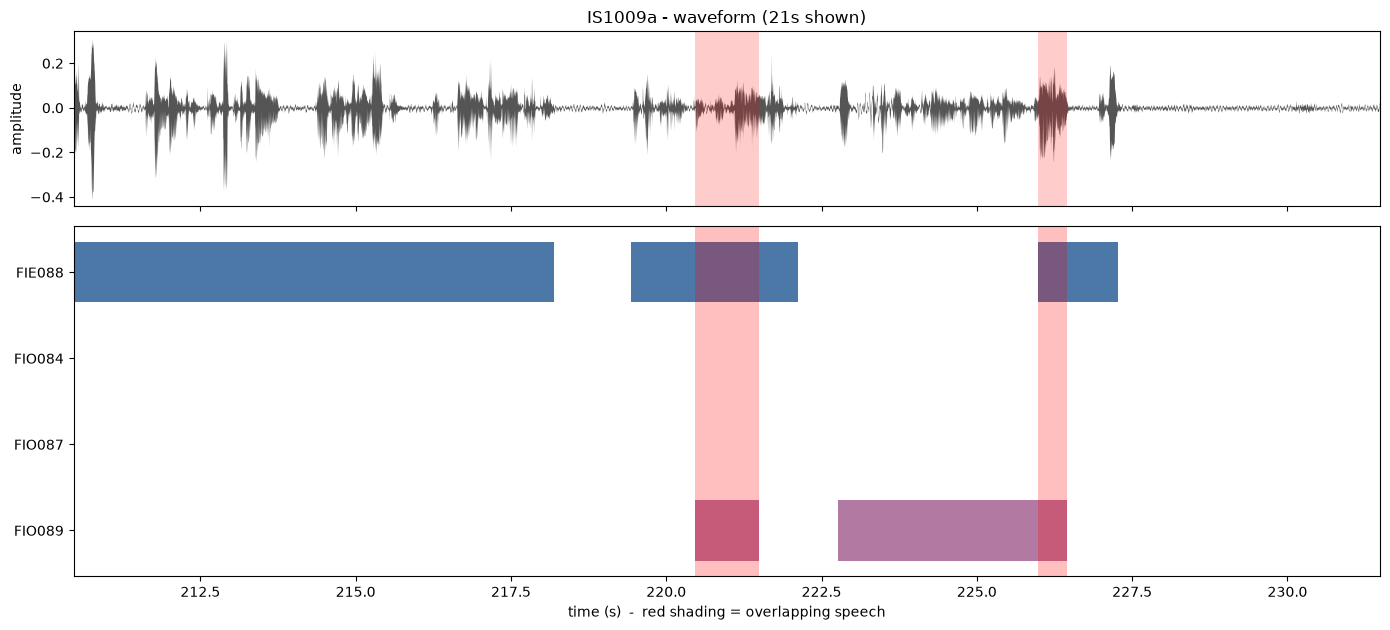

TS3003a: 12 overlap regions > 1 s; zooming on 111.3-113.5s


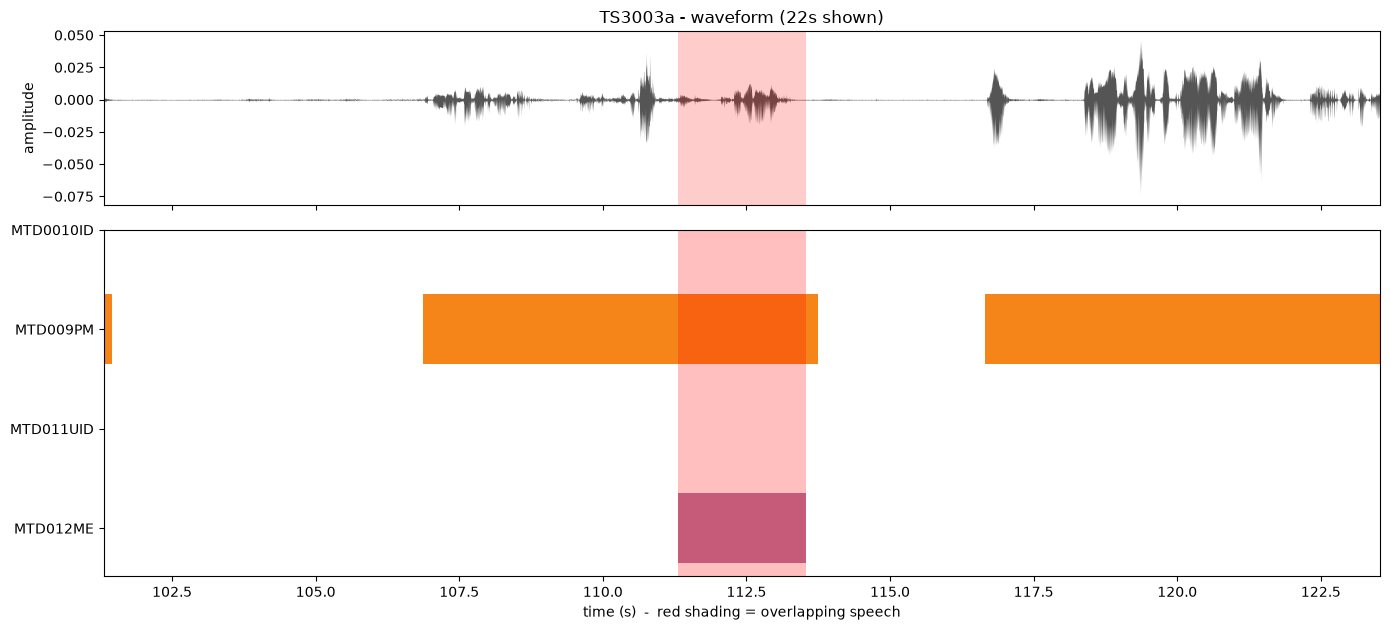

In [4]:
for rid in manifest.recording_id:
    _, _, df = load(rid)
    ov = [r for r in overlap_regions(df) if r[1] - r[0] > 1.0]
    a, b = ov[0]
    print(f"{rid}: {len(ov)} overlap regions > 1 s; zooming on {a:.1f}-{b:.1f}s")
    plot_recording(rid, max(0, a - 10), b + 10)
    play(rid, max(0, a - 3), b + 3)

## Speaker count and overlap overview

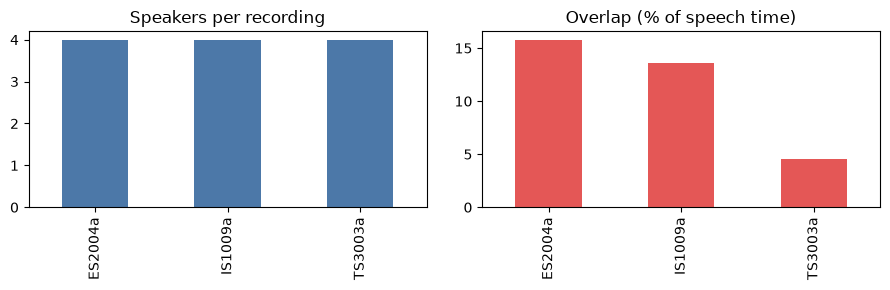

In [5]:
overview = manifest.set_index("recording_id")[["num_speakers", "overlap_ratio_of_speech"]]
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
overview.num_speakers.plot.bar(ax=ax[0], color="#4C78A8", title="Speakers per recording")
(overview.overlap_ratio_of_speech * 100).plot.bar(ax=ax[1], color="#E45756", title="Overlap (% of speech time)")
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.show()